# Projeto 16: Chatbot com Controle de Orçamento

PUC-SP, Ciência da Computação, Inteligência Artificial

Dupla: Luan Bonasorte Capella e Matheus Heimrath Barbosa

O chatbot mostra quantos tokens cada mensagem gastou e quanto isso custou em dólares. Como a API não guarda a conversa, o histórico inteiro é reenviado a cada pergunta e o custo vai subindo. Para evitar isso, quando o histórico passa de um limite de tokens, as mensagens antigas são resumidas.

## Instalação e chave da API

A chave fica nos Secrets do Colab com o nome `OPENAI_API_KEY`.

In [9]:
%pip install -q openai pandas matplotlib

No Colab, use **Ambiente de execução > Alterar tipo > GPU T4** para ficar mais rápido. A célula abaixo instala o Ollama e baixa o modelo.

In [10]:
# Instala e inicia o Ollama dentro do Colab (roda a cada nova sessão; leva alguns minutos)
!apt-get install -y -qq zstd pciutils > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1

import subprocess, time, urllib.request
subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(30):   # espera o servidor subir
    try:
        urllib.request.urlopen("http://localhost:11434"); break
    except Exception:
        time.sleep(1)

!ollama pull llama3.2:3b

In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI

# Ollama roda localmente e expõe uma API compatível com a da OpenAI (sem chave de verdade)
client = OpenAI(base_url="http://localhost:11434/v1", api_key="ollama")

## Configuração

Preço do gpt-5-nano em dólares por 1 milhão de tokens (mesmo valor usado na aula).

In [12]:
MODELO = "llama3.2:3b"   # modelo local (ollama pull llama3.2:3b)
# O Ollama é grátis; estes preços são de REFERÊNCIA (os do gpt-5-nano) só para simular o custo
PRECO_ENTRADA = 0.05   # por 1M tokens de entrada
PRECO_SAIDA = 0.40     # por 1M tokens de saída

LIMITE_TOKENS = 1000   # passou disso, resume o histórico
MANTER = 4             # quantas mensagens recentes ficam sem resumir

def calcular_custo(tokens_entrada, tokens_saida):
    return (tokens_entrada * PRECO_ENTRADA + tokens_saida * PRECO_SAIDA) / 1_000_000

## Classe do chatbot

A cada mensagem, o método `falar` envia o histórico, pega os tokens no campo `usage` da resposta e soma o custo. Se passar do limite, chama `resumir`, que pede ao próprio modelo um resumo das mensagens antigas. O resumo também tem custo, então ele entra na conta.

In [13]:
class ChatOrcamento:
    def __init__(self, sistema, limite=LIMITE_TOKENS):
        self.sistema = sistema
        self.limite = limite
        self.mensagens = []
        self.resumo = ""
        self.custo_total = 0.0
        self.turno = 0
        self.registros = []   # uma linha por chamada na API

    def chamar_api(self, instrucoes, entrada, tipo):
        if isinstance(entrada, str):
            entrada = [{"role": "user", "content": entrada}]
        resposta = client.chat.completions.create(
            model=MODELO,
            messages=[{"role": "system", "content": instrucoes}] + entrada,
            max_tokens=250,
        )
        entrada_tk = resposta.usage.prompt_tokens
        saida_tk = resposta.usage.completion_tokens
        custo = calcular_custo(entrada_tk, saida_tk)
        self.custo_total += custo

        self.registros.append({
            "turno": self.turno,
            "tipo": tipo,
            "tokens_entrada": entrada_tk,
            "tokens_saida": saida_tk,
            "custo": custo,
            "custo_acumulado": self.custo_total,
        })
        return resposta.choices[0].message.content, entrada_tk, saida_tk, custo

    def resumir(self):
        antigas = self.mensagens[:-MANTER]
        recentes = self.mensagens[-MANTER:]

        texto = self.resumo + "\n"
        for m in antigas:
            texto += m["role"] + ": " + m["content"] + "\n"

        instrucoes = ("Resuma esta conversa em até 80 palavras, em português. "
                      "Não esqueça fatos sobre o usuário, como nome e objetivos.")
        novo_resumo, _, _, custo = self.chamar_api(instrucoes, texto, "resumo")

        self.resumo = novo_resumo
        self.mensagens = recentes
        print(f"  [histórico resumido, custo do resumo: US$ {custo:.6f}]")

    def falar(self, texto, mostrar=True):
        self.turno += 1
        self.mensagens.append({"role": "user", "content": texto})

        # o resumo vai junto com as instruções do sistema
        instrucoes = self.sistema
        if self.resumo:
            instrucoes += "\n\nResumo da conversa até agora: " + self.resumo

        resposta, entrada_tk, saida_tk, custo = self.chamar_api(instrucoes, self.mensagens, "chat")
        self.mensagens.append({"role": "assistant", "content": resposta})

        if mostrar:
            print("você:", texto)
            print("bot:", resposta)
            print(f"  [{entrada_tk} tokens de entrada, {saida_tk} de saída, "
                  f"custo US$ {custo:.6f}, total US$ {self.custo_total:.6f}]")

        if entrada_tk + saida_tk > self.limite:
            self.resumir()
        if mostrar:
            print()
        return resposta

    def tabela(self):
        return pd.DataFrame(self.registros)

## Teste com uma conversa

No primeiro turno a pessoa fala o nome e onde estuda. No último, perguntamos isso de volta para ver se o bot lembrou mesmo depois do resumo.

In [14]:
chat = ChatOrcamento("Você é um tutor de computação. Responda em português, em até 120 palavras.")

perguntas = [
    "Oi, meu nome é Ada, estudo Ciência da Computação na PUC-SP e quero trabalhar com dados.",
    "O que é uma Web API REST?",
    "Qual a diferença entre GET e POST?",
    "Como funciona autenticação com Bearer token?",
    "Por que dizem que a API de um LLM é stateless?",
    "Por que um chatbot fica mais caro quando a conversa cresce?",
    "Quando usar temperatura 0 em um LLM?",
    "O que é streaming de tokens?",
    "Como funciona tool calling com SQL?",
    "Por que não deixar o modelo rodar comandos de escrita no banco?",
    "Para que serve structured output com Pydantic?",
    "Qual é o meu nome, onde eu estudo e com o que quero trabalhar?",
]

for p in perguntas:
    chat.falar(p)

você: Oi, meu nome é Ada, estudo Ciência da Computação na PUC-SP e quero trabalhar com dados.
bot: Olá Ada! É ótimo saber que você está estudando Ciência da Computação na PUC-SP e que tem interesse em trabalhar com dados! Esse é um campo muito dinâmico e cheio de oportunidades.

Você pode começar explorando as áreas de análise de dados, aprendizado de máquina, visuais e inteligência artificial. Existem muitas bibliotecas e ferramentas úteis para começar, como Python, R, Pandas, NumPy e Matplotlib.

Qual é o seu próximo passo? Você está procurando saber mais sobre algum desses tópicos ou tem alguma pergunta específica?
  [75 tokens de entrada, 141 de saída, custo US$ 0.000060, total US$ 0.000060]

você: O que é uma Web API REST?
bot: Excelente pergunta, Ada!

Uma Web API REST (Representational State of Resource) é uma arquitetura de serviços de rede que fornece uma forma estruturada e consistente de interagir com recursos ( dados ) em um sistema.

Aqui estão os principais conceitos de u

## Tabela de custos

In [15]:
tabela = chat.tabela()
print(tabela)
print()
print(f"Custo total: US$ {chat.custo_total:.6f}")
print("Chamadas de resumo:", (tabela["tipo"] == "resumo").sum())

    turno    tipo  tokens_entrada  tokens_saida     custo  custo_acumulado
0       1    chat              75           141  0.000060         0.000060
1       2    chat             233           250  0.000112         0.000172
2       3    chat             503           250  0.000125         0.000297
3       4    chat             773           250  0.000139         0.000436
4       4  resumo             492           137  0.000079         0.000515
5       5    chat             748           250  0.000137         0.000652
6       6    chat            1024           250  0.000151         0.000804
7       6  resumo             724           136  0.000091         0.000894
8       7    chat             753           250  0.000138         0.001032
9       7  resumo             463            93  0.000060         0.001092
10      8    chat             702           250  0.000135         0.001227
11      9    chat             969           250  0.000148         0.001376
12      9  resumo        

## Gráficos

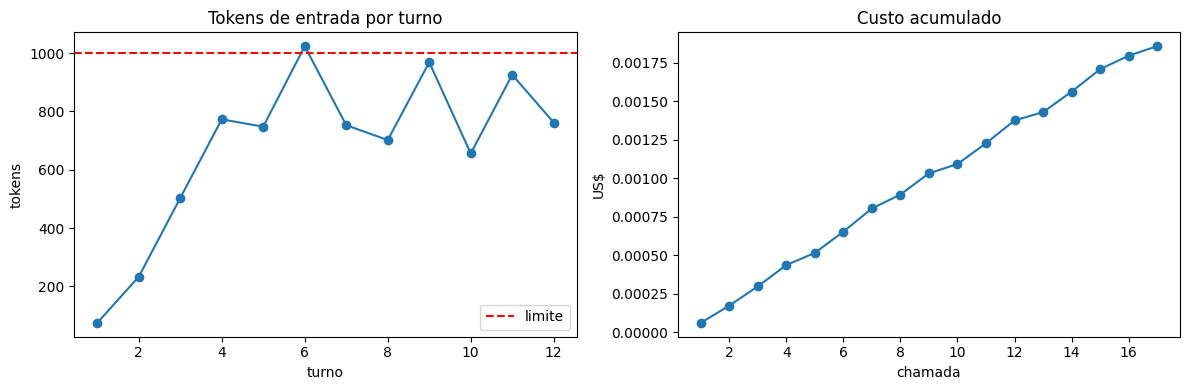

In [16]:
so_chat = tabela[tabela["tipo"] == "chat"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(so_chat["turno"], so_chat["tokens_entrada"], marker="o")
ax1.axhline(LIMITE_TOKENS, color="red", linestyle="--", label="limite")
ax1.set_title("Tokens de entrada por turno")
ax1.set_xlabel("turno")
ax1.set_ylabel("tokens")
ax1.legend()

ax2.plot(range(1, len(tabela) + 1), tabela["custo_acumulado"], marker="o")
ax2.set_title("Custo acumulado")
ax2.set_xlabel("chamada")
ax2.set_ylabel("US$")

plt.tight_layout()
plt.show()

## Comparação sem resumo

Mesmas perguntas, mas com um limite gigante para o resumo nunca acontecer.

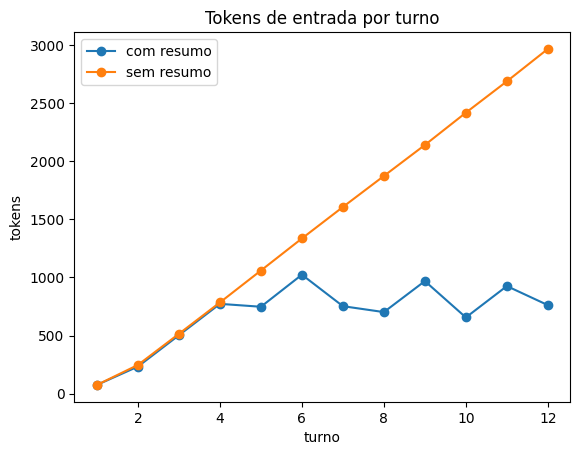

Com resumo: US$ 0.001858
Sem resumo: US$ 0.001961


In [17]:
sem_resumo = ChatOrcamento(chat.sistema, limite=10**9)
for p in perguntas:
    sem_resumo.falar(p, mostrar=False)

t2 = sem_resumo.tabela()
plt.plot(so_chat["turno"], so_chat["tokens_entrada"], marker="o", label="com resumo")
plt.plot(t2["turno"], t2["tokens_entrada"], marker="o", label="sem resumo")
plt.title("Tokens de entrada por turno")
plt.xlabel("turno")
plt.ylabel("tokens")
plt.legend()
plt.show()

print(f"Com resumo: US$ {chat.custo_total:.6f}")
print(f"Sem resumo: US$ {sem_resumo.custo_total:.6f}")

## Chat livre

Digite `sair` para parar.

In [18]:
meu_chat = ChatOrcamento("Você é um assistente simpático. Responda em português, de forma curta.")

while True:
    texto = input("você: ")
    if texto.strip().lower() == "sair":
        break
    meu_chat.falar(texto)

print(meu_chat.tabela())

você: Meu nome é Ana e eu gosto de gatos. Responda em uma frase.
você: Meu nome é Ana e eu gosto de gatos. Responda em uma frase.
bot: Que maravilha! Gatos são animais incríveis e tão adoráveis, não é?
  [66 tokens de entrada, 22 de saída, custo US$ 0.000012, total US$ 0.000012]

você: Cite 3 raças de gato, só os nomes.
você: Cite 3 raças de gato, só os nomes.
bot: Ragdoll
Persa
Siamesa
  [112 tokens de entrada, 11 de saída, custo US$ 0.000010, total US$ 0.000022]

você: Cite 3 linguagens de programação, só os nomes.
você: Cite 3 linguagens de programação, só os nomes.
bot: Java
Python
C++
  [147 tokens de entrada, 7 de saída, custo US$ 0.000010, total US$ 0.000032]

você: Qual é o meu nome e do que eu gosto?
você: Qual é o meu nome e do que eu gosto?
bot: Você é Ana e gosta de gatos!
  [175 tokens de entrada, 11 de saída, custo US$ 0.000013, total US$ 0.000045]

você: sair
   turno  tipo  tokens_entrada  tokens_saida     custo  custo_acumulado
0      1  chat              66           

## Conclusão

Sem o resumo, os tokens de entrada aumentam a cada turno, porque o histórico todo é mandado de novo. Com o resumo, eles caem sempre que o limite é atingido, e o custo total cresce mais devagar.

O resumo também custa e pode perder detalhes da conversa. Por isso pedimos no prompt para manter os fatos sobre o usuário, e a última pergunta do teste serve para conferir isso.